# Hierarchical clustering from scratch

This notebook rebuilds what the library lab [`hierarchical_lab.ipynb`](hierarchical_lab.ipynb) uses, with nothing but NumPy, and checks each
result against scikit-learn or SciPy on the same data. The theory is in [README §4](../../README.md#4-hierarchical-agglomerative-clustering).

Part of the [clustering labs](../README.md), one folder per method: [k-means](../01-kmeans/kmeans_lab.ipynb) · [hierarchical](../02-hierarchical/hierarchical_lab.ipynb) · [DBSCAN](../03-dbscan/dbscan_lab.ipynb) · [OPTICS / HDBSCAN](../04-optics-hdbscan/optics_hdbscan_lab.ipynb) · [in practice](../05-in-practice/in_practice_lab.ipynb).

**How to use it**

1. Run the first code cell (imports and helpers), then run top to bottom (**Run All**). Later cells reuse functions
   from earlier ones.
2. Each section has the same shape: the algorithm in plain steps (markdown) → the code, commented line by line →
   a **comparison with the library** → a "How to read this" box.
3. Boxes titled **Implementation hurdle** show a real problem you hit when writing this yourself, demonstrated on a
   small case and then fixed.
4. scikit-learn and SciPy are imported **only to check** our answers. No internet needed.

| Section | Algorithm | Checked against |
|---|---|---|
| [agglomerative](#sec-3) | agglomerative clustering with the Lance–Williams update | `scipy.cluster.hierarchy.linkage` |
| [Summary](#summary) | what matched, and the hurdles | |

**Two distance helpers** (defined in the first code cell):

* `exact_distances(X)` subtracts the points directly: slower, but exact, which matters when distances between points
  are compared with each other. The algorithm uses this one.
* `pairwise_distances(A, B)` uses $\lVert a - b \rVert^2 = \lVert a \rVert^2 - 2\,a \cdot b + \lVert b \rVert^2$, the fast trick k-means uses.
  The ties hurdle below shows what its rounding does to the tree.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

# scikit-learn / SciPy are imported ONLY to check our answers against theirs; every algorithm below is plain NumPy.
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from sklearn.datasets import load_iris
from sklearn.metrics import adjusted_rand_score


np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0


def pairwise_distances(A, B):
    """Euclidean distance between every row of A (n x d) and every row of B (m x d) -> an n x m matrix.

    Uses ||a - b||² = ||a||² - 2 a·b + ||b||², which needs only an n x m matrix in memory, instead of the
    n x m x d array that `A[:, None, :] - B[None, :, :]` would build (see the memory
    hurdle in the k-means from-scratch notebook)."""
    squared = (A ** 2).sum(axis=1)[:, None] - 2 * A @ B.T + (B ** 2).sum(axis=1)[None, :]
    return np.sqrt(np.maximum(squared, 0))          # rounding can make a true 0 come out as -1e-15; clip it to 0


def exact_distances(X):
    """All point-to-point distances computed from the differences themselves (n x n x d in memory, fine for a few
    thousand points). Slower than the trick above, but exact to the last digit, which matters when distances TIE
    (see the ties hurdle below)."""
    return np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))

<a id="sec-3"></a>

## Agglomerative (hierarchical) clustering

**README §4.** Start with every point as its own cluster. Repeat n − 1 times: find the two **closest clusters**, merge
them, and record the merge as one row of the **linkage matrix** `[cluster 1, cluster 2, distance, new size]` (SciPy's
format, so SciPy's `dendrogram` can draw our result).

"Closest" depends on the linkage. Recomputing it from all the points after every merge would be slow, so we use the
**Lance–Williams update**: the distance from the merged cluster $A \cup B$ to any other cluster $C$ follows from the
three distances we already have, $d(A, C)$, $d(B, C)$ and $d(A, B)$:

| Linkage | $d(A \cup B,\ C)$ |
|---|---|
| single | $\min\big(d(A,C),\ d(B,C)\big)$ |
| complete | $\max\big(d(A,C),\ d(B,C)\big)$ |
| average | $\dfrac{\lvert A\rvert\, d(A,C) + \lvert B\rvert\, d(B,C)}{\lvert A\rvert + \lvert B\rvert}$ |
| ward | $\sqrt{\dfrac{(\lvert A\rvert + \lvert C\rvert)\, d(A,C)^2 + (\lvert B\rvert + \lvert C\rvert)\, d(B,C)^2 - \lvert C\rvert\, d(A,B)^2}{\lvert A\rvert + \lvert B\rvert + \lvert C\rvert}}$ |

The ward formula is SciPy's version on plain (not squared) distances. Each merge scans all living pairs, so this naive
version costs about $n^3$ operations: fine for hundreds of points, too slow for tens of thousands. Data: the 150 iris
flowers (4 measurements, all in cm, so no scaling needed).

method     largest merge-height difference vs SciPy   same 3-cluster partition (ARI = 1)   seconds (ours / SciPy)
single          0.0e+00                              True                               0.01 / 0.0003
complete        0.0e+00                              True                               0.01 / 0.0002
average         8.9e-16                              True                               0.01 / 0.0002
ward            1.8e-15                              True                               0.01 / 0.0002


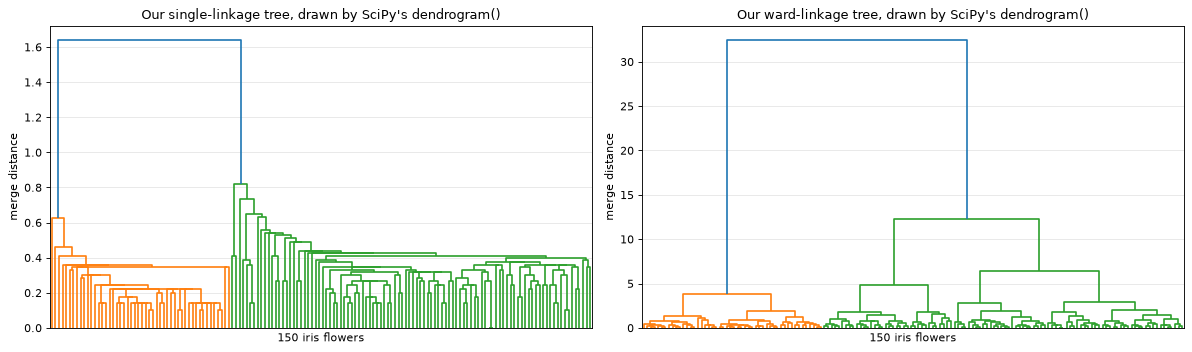

In [2]:
def lance_williams(method, d_ac, d_bc, d_ab, n_a, n_b, n_c):
    """Distance from the merged cluster (A ∪ B) to another cluster C, from distances already known.
    This one formula per linkage is what lets agglomerative clustering avoid recomputing point distances."""
    if method == "single":
        return min(d_ac, d_bc)                                   # closest pair
    if method == "complete":
        return max(d_ac, d_bc)                                   # farthest pair
    if method == "average":
        return (n_a * d_ac + n_b * d_bc) / (n_a + n_b)           # size-weighted average of the two averages
    if method == "ward":                                         # SciPy's form, on (not squared) distances
        total = n_a + n_b + n_c
        return np.sqrt(((n_a + n_c) * d_ac ** 2 + (n_b + n_c) * d_bc ** 2 - n_c * d_ab ** 2) / total)
    raise ValueError(method)


def agglomerative(X, method, point_distances=None):
    """Naive agglomerative clustering. Returns a SciPy-style linkage matrix: one row per merge,
    [id of cluster 1, id of cluster 2, merge distance, size of the new cluster].
    Points have ids 0..n-1; the cluster made by merge m gets id n + m.
    `point_distances` (optional, n x n) replaces the exact distances; only used for the rounding hurdle below."""
    n = len(X)
    D = np.full((2 * n - 1, 2 * n - 1), np.inf)              # room for all n points and all n-1 merged clusters
    D[:n, :n] = exact_distances(X) if point_distances is None else point_distances
    np.fill_diagonal(D, np.inf)                              # a cluster is never merged with itself
    size = np.zeros(2 * n - 1, dtype=int); size[:n] = 1
    alive = list(range(n))                                   # ids of the clusters that still exist
    Z = []
    for m in range(n - 1):
        sub = D[np.ix_(alive, alive)]                        # distances among living clusters only
        flat = np.argmin(sub)                                # the closest pair (first one, if there are ties)
        a, b = alive[flat // len(alive)], alive[flat % len(alive)]
        new = n + m
        for c in alive:                                      # distance from the new cluster to every other cluster
            if c not in (a, b):
                D[new, c] = D[c, new] = lance_williams(method, D[a, c], D[b, c], D[a, b], size[a], size[b], size[c])
        Z.append([min(a, b), max(a, b), D[a, b], size[a] + size[b]])
        size[new] = size[a] + size[b]
        alive = [c for c in alive if c not in (a, b)] + [new]
    return np.array(Z, dtype=float)


def cut_into_k(Z, k):
    """Flat clusters from a linkage matrix: replay the first n - k merges and label each point by its group."""
    n = len(Z) + 1
    members = {i: [i] for i in range(n)}                     # cluster id -> the points in it; starts as singletons
    for m, (a, b, _, _) in enumerate(Z[: n - k]):            # merge m joins clusters a and b into cluster n + m
        members[n + m] = members.pop(int(a)) + members.pop(int(b))
    labels = np.empty(n, dtype=int)
    for label, points in enumerate(members.values()):
        labels[points] = label
    return labels


iris_X = load_iris().data                                        # 150 flowers, 4 measurements, all in cm
print("method     largest merge-height difference vs SciPy   same 3-cluster partition (ARI = 1)   seconds (ours / SciPy)")
our_trees = {}
for method in ["single", "complete", "average", "ward"]:
    t0 = time.perf_counter(); Z_ours = agglomerative(iris_X, method); t_ours = time.perf_counter() - t0
    t0 = time.perf_counter(); Z_scipy = linkage(iris_X, method=method); t_scipy = time.perf_counter() - t0
    our_trees[method] = Z_ours
    height_gap = np.abs(np.sort(Z_ours[:, 2]) - np.sort(Z_scipy[:, 2])).max()
    same = adjusted_rand_score(cut_into_k(Z_ours, 3), fcluster(Z_scipy, 3, criterion="maxclust")) == 1.0
    print(f"{method:9s}  {height_gap:12.1e}                              {str(same):5s}"
          f"                              {t_ours:.2f} / {t_scipy:.4f}")
    assert height_gap < 1e-9 and same

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, method in zip(axes, ["single", "ward"]):
    dendrogram(our_trees[method], ax=ax, no_labels=True, color_threshold=None)
    ax.set_xlabel("150 iris flowers"); ax.set_ylabel("merge distance")
    ax.set_title(f"Our {method}-linkage tree, drawn by SciPy's dendrogram()")
plt.tight_layout(); plt.show()

> **How to read this**
> * For all four linkages, every merge height equals SciPy's (largest difference **1.8e-15**, rounding) and cutting the
>   tree into 3 clusters gives exactly SciPy's partition. The `assert` checks both.
> * Our trees, drawn with SciPy's `dendrogram()`. Single linkage shows the typical chaining: flowers join the two big
>   groups one at a time in a long staircase, and only setosa stands clearly apart. Ward splits setosa off at the top
>   (height about 32) and then the other two species (about 12): three groups.
> * Ours is far slower than SciPy (see the printed seconds; yours will differ). SciPy uses smarter algorithms (a
>   minimum spanning tree for single linkage, nearest-neighbour chains for the others) and compiled code.

> **Implementation hurdle — ties, and the rounding that decides them.** When two pairs are exactly equally close, which
> one is merged first is a free choice: the heights come out the same, but the rows of the linkage matrix can be in a
> different order. Measurements rounded to 0.1 cm produce *many* exact ties. And if distances are computed with the fast
> expansion trick, rounding errors decide the ties at random, which can produce a genuinely **different tree**.

In [3]:
# Two pairs at exactly the same distance: which pair is merged first is a tie
X_tie = np.array([[0.0, 0.0], [1.0, 0.0], [5.0, 0.0], [6.0, 0.0]])
print("ours :\n", agglomerative(X_tie, "single"))
print("SciPy:\n", linkage(X_tie, method="single"))
iris_rows_equal = {m: bool(np.allclose(our_trees[m], linkage(iris_X, method=m))) for m in our_trees}
print("\niris: linkage matrices identical row by row?", iris_rows_equal)

# Rounding decides ties: the fast distance trick is off by ~1e-15, enough to change which tied pair looks smaller
D_exact, D_fast = exact_distances(iris_X), pairwise_distances(iris_X, iris_X)
iu = np.triu_indices(len(iris_X), k=1)
values = D_exact[iu]
tied = len(values) - len(np.unique(values))
print(f"\niris has {len(values)} distinct pairs of flowers, and {tied} of their distances repeat an earlier value exactly")
print(f"largest gap between the fast and the exact distances: {np.abs(D_exact - D_fast).max():.1e}")
Z_fast = agglomerative(iris_X, "complete", point_distances=D_fast)
print("complete linkage built from the FAST distances: largest merge-height difference vs SciPy "
      f"{np.abs(np.sort(Z_fast[:, 2]) - np.sort(linkage(iris_X, 'complete')[:, 2])).max():.3f}")

ours :
 [[0. 1. 1. 2.]
 [2. 3. 1. 2.]
 [4. 5. 4. 4.]]
SciPy:
 [[0. 1. 1. 2.]
 [2. 3. 1. 2.]
 [4. 5. 4. 4.]]

iris: linkage matrices identical row by row? {'single': False, 'complete': False, 'average': True, 'ward': False}

iris has 11175 distinct pairs of flowers, and 5611 of their distances repeat an earlier value exactly
largest gap between the fast and the exact distances: 1.7e-07
complete linkage built from the FAST distances: largest merge-height difference vs SciPy 0.116


> **How to read this**
> * The tiny example (two pairs at distance exactly 1) happens to merge in the same order as SciPy.
> * On iris, the linkage matrices are identical **row by row** only for average linkage; for single, complete and ward
>   the tied merges come in a different order. The heights and the 3-cluster partitions are still identical (cell
>   above).
> * Iris has **11175** pairs of flowers, and **5611** of their distances repeat an earlier value exactly.
> * The fast distances differ from the exact ones by up to **1.7e-7**, which is enough to break those ties differently:
>   complete linkage built from them gives merge heights up to **0.116** away from SciPy's. That's why the tree,
>   DBSCAN and OPTICS use `exact_distances`.

---

<a id="summary"></a>

## Summary

| Section | Our implementation | Matches the library? | Hurdle shown |
|---|---|---|---|
| [agglomerative](#sec-3) | agglomerative with Lance–Williams, 4 linkages | ✔ identical merge heights and partitions | ties: row order; rounding changes the tree |